# National Registry (TSE Padrón) analysis with pandas

Explores `PADRON_COMPLETO.txt` from Costa Rica's Tribunal Supremo de Elecciones (TSE). ~3.7M records.

**`PADRON_COMPLETO.txt`** (comma-separated, space-padded, ISO-8859-1 / latin1):

| # | Column | Len | Description |
|---|--------|-----|-------------|
| 0 | `cedula` | 9 | National ID |
| 1 | `codelec` | 6 | Electoral code: province(1) + canton(2) + district(3) |
| 2 | `_filler` | 1 | **Empty** (TSE `RELLENO` field. btw There is no sex column) |
| 3 | `expiry` | 8 | ID expiry date (`YYYYMMDD`) |
| 4 | `_precinct` | 5 | Polling station `00000` here (only set at election close) |
| 5 | `name` | 30 | Given name(s) |
| 6 | `surname1` | 26 | First surname |
| 7 | `surname2` | 26 | Second surname |

**`distelec.txt`** maps `codelec → province, canton, district` names


> Files (~430 MB) are **not versioned**. Download `padron_completo.zip` from <https://www.tse.go.cr/descarga_padron.html>, unzip, and drop `PADRON_COMPLETO.txt` + `distelec.txt` in `apps/restapi/datasets/` (or set `PADRON_PATH`).

In [11]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# With 3.7M rows, axis ticks default to scientific notation (1e6). These force
# plain, thousands-separated integers on whichever axis holds the counts.
thousands = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
plain_int = mticker.FuncFormatter(lambda x, _: f"{int(x)}")


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until the monorepo root is found."""
    for p in [start, *start.parents]:
        if (p / "apps" / "restapi").exists():
            return p
    raise FileNotFoundError("Could not locate the repo root (apps/restapi)")


REPO_ROOT = find_repo_root(Path.cwd())
DATASETS = REPO_ROOT / "apps/restapi/datasets"
PADRON_PATH = Path(os.environ.get("PADRON_PATH", DATASETS / "PADRON_COMPLETO.txt"))
DISTELEC_PATH = PADRON_PATH.parent / "distelec.txt"

# For fast iteration set a number (e.g. 200_000); None = full file.
NROWS = None

assert PADRON_PATH.exists(), (
    f"Padrón file not found at {PADRON_PATH}.\n"
    "Download it from https://www.tse.go.cr/descarga_padron.html, unzip it, "
    "and place PADRON_COMPLETO.txt there (or set the PADRON_PATH env var)."
)
print(f"Reading: {PADRON_PATH}  ({PADRON_PATH.stat().st_size / 1e6:.0f} MB)")

Reading: /home/juanes/Documents/uni/2026/proyecto-anual/monorepo/apps/restapi/datasets/PADRON_COMPLETO.txt  (449 MB)


In [12]:
# Columns 2 (_filler) and 4 (_precinct) are blank here — kept for positional
# alignment, dropped right after.
COLUMNS = [
    "cedula", "codelec", "_filler", "expiry", "_precinct",
    "name", "surname1", "surname2",
]

df = pd.read_csv(
    PADRON_PATH,
    sep=",",
    names=COLUMNS,
    header=None,
    dtype=str,            # keep everything as text: IDs/codes are not numbers
    encoding="latin1",    # ISO-8859-1: preserves accents and ñ
    skipinitialspace=True,
    nrows=NROWS,
    on_bad_lines="skip",
)
df = df.drop(columns=["_filler", "_precinct"])

# The file is space-padded: strip every text column.
for col in df.columns:
    df[col] = df[col].str.strip()

print(f"{len(df):,} records")
df.head()

3,745,578 records


,cedula,codelec,expiry,name,surname1,surname2
0,101053316,104015,20280207,LUCILA,PORRAS,AGUERO
1,101240037,823001,20300204,ANA MARIA,PEREZ,PEREZ
2,101280947,103008,20261019,GERMAN,CARVAJAL,BERMUDEZ
3,101290149,101010,20300204,JOSE VICENTE,ACUÑA,ACUÑA
4,101290354,104014,20270331,BENITIVO,ARIAS,CAMPOS


In [13]:
# distelec.txt: codelec, province, canton, district (latin1, comma-separated).
# A few district names contain commas, so we split on the FIRST 3 commas only —
# the district field absorbs the rest. (read_csv would choke on those lines.)
def load_distelec(path: Path) -> pd.DataFrame:
    rows = []
    with open(path, encoding="latin1") as fh:
        for line in fh:
            parts = line.rstrip("\n").split(",", 3)
            if len(parts) == 4:
                rows.append([p.strip() for p in parts])
    return pd.DataFrame(rows, columns=["codelec", "province", "canton", "district"])


distelec = load_distelec(DISTELEC_PATH)
print(f"{len(distelec):,} electoral districts")

# Left join: every padrón row gains province / canton / district names.
df = df.merge(distelec, on="codelec", how="left")
unmatched = df["province"].isna().sum()
print(f"Rows with no district match: {unmatched:,}")
df[["cedula", "codelec", "province", "canton", "district"]].head()

2,179 electoral districts
Rows with no district match: 0


,cedula,codelec,province,canton,district
0,101053316,104015,SAN JOSE,PURISCAL,GRIFO ALTO
1,101240037,823001,CONSULADO,MEXICO,CIUDAD DE MEXICO
2,101280947,103008,SAN JOSE,DESAMPARADOS,SAN ANTONIO
3,101290149,101010,SAN JOSE,CENTRAL,PASO ANCHO SUR
4,101290354,104014,SAN JOSE,PURISCAL,SAN JUAN


In [14]:
# --- Derived columns ---
df["expiry_date"] = pd.to_datetime(df["expiry"], format="%Y%m%d", errors="coerce")
df["expiry_year"] = df["expiry_date"].dt.year

# Given name (first token of the name field) for frequency analysis
df["first_name"] = df["name"].str.split().str[0]

df[["cedula", "province", "canton", "expiry_date", "first_name"]].head()

,cedula,province,canton,expiry_date,first_name
0,101053316,SAN JOSE,PURISCAL,2028-02-07,LUCILA
1,101240037,CONSULADO,MEXICO,2030-02-04,ANA
2,101280947,SAN JOSE,DESAMPARADOS,2026-10-19,GERMAN
3,101290149,SAN JOSE,CENTRAL,2030-02-04,JOSE
4,101290354,SAN JOSE,PURISCAL,2027-03-31,BENITIVO


## Overview

In [15]:
print(f"Total people in the registry: {len(df):,}")
print(f"Unique IDs:                   {df['cedula'].nunique():,}")
print(f"Provinces / cantons / districts: "
      f"{df['province'].nunique()} / {df['canton'].nunique()} / {df['district'].nunique()}")
print(f"Expiry range: {df['expiry_date'].min():%Y-%m-%d}  →  {df['expiry_date'].max():%Y-%m-%d}")

Total people in the registry: 3,745,578
Unique IDs:                   3,745,578
Provinces / cantons / districts: 8 / 121 / 1701
Expiry range: 2026-06-01  →  2036-05-31


## Distribution by province

province
SAN JOSE      1191756
ALAJUELA       728910
CARTAGO        429937
HEREDIA        379460
PUNTARENAS     352895
LIMON          315342
GUANACASTE     280761
CONSULADO       66517
Name: count, dtype: int64


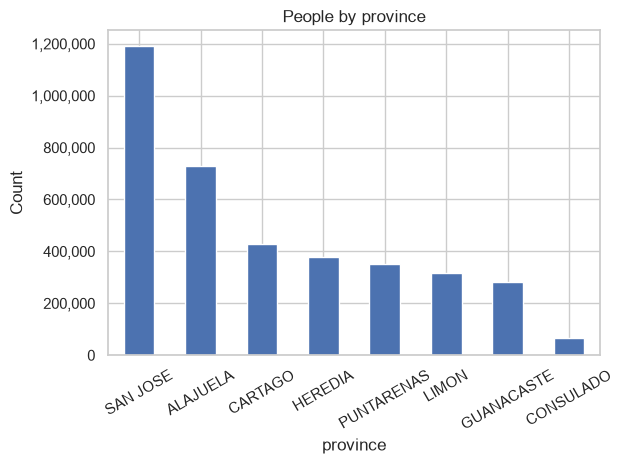

In [ ]:
prov_counts = df["province"].value_counts()
print(prov_counts)

ax = prov_counts.plot.bar(color="#4C72B0", rot=30)
ax.set_title("People by province")
ax.set_ylabel("Count")
ax.yaxis.set_major_formatter(thousands)

plt.tight_layout()
plt.show()

## Top 20 cantons

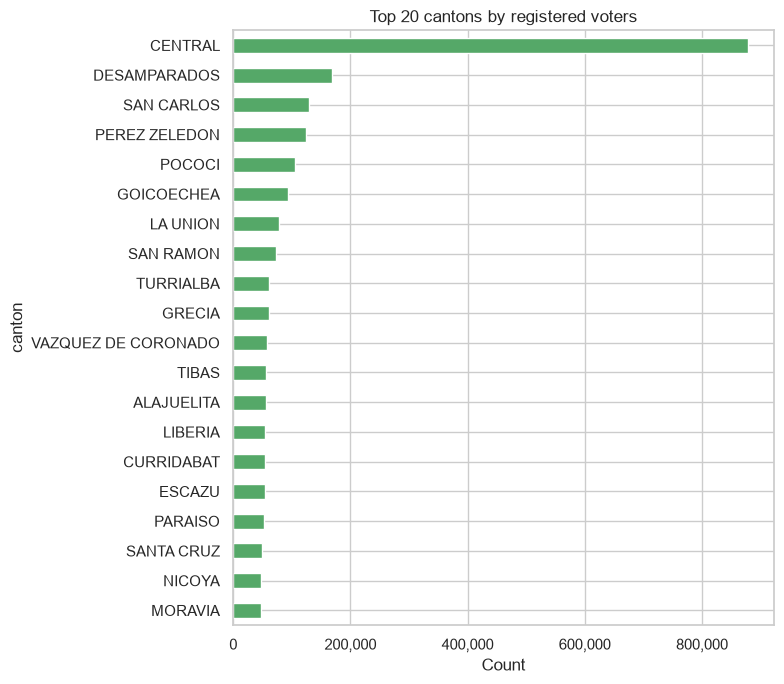

In [ ]:
top_cantons = df["canton"].value_counts().head(20)

ax = top_cantons.sort_values().plot.barh(color="#55A868", figsize=(8, 7))
ax.set_title("Top 20 cantons by registered voters")
ax.set_xlabel("Count")
ax.xaxis.set_major_formatter(thousands)

plt.tight_layout()
plt.show()

## Most frequent names and surnames

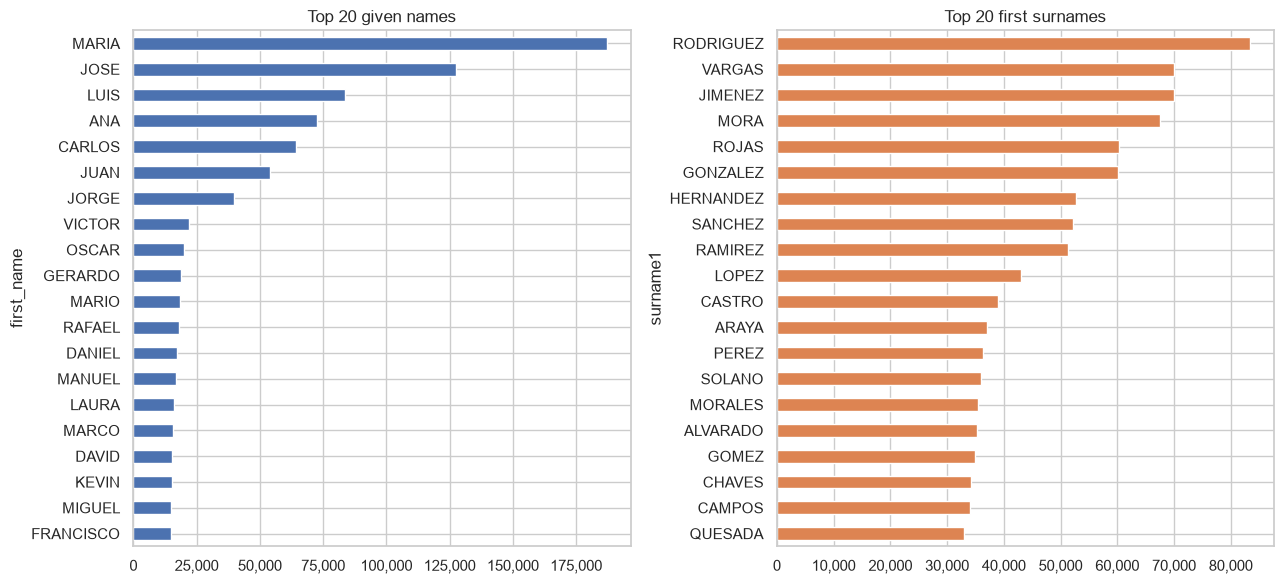

In [ ]:
top_names = df["first_name"].value_counts().head(20)
top_surnames = df["surname1"].value_counts().head(20)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
# Plot 1
top_names.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Top 20 given names")
axes[0].xaxis.set_major_formatter(thousands)

# Plot 2
top_surnames.sort_values().plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("Top 20 first surnames")
axes[1].xaxis.set_major_formatter(thousands)

plt.tight_layout()
plt.show()